# Risk vs. Return: Volatility and Portfolio Optimization

This notebook has two parts:

1. **A controlled illustration:** simulate two investments with the same assumed average daily return but different volatility, then compare their realized paths.
2. **Historical portfolio optimization:** use adjusted prices for AAPL, MSFT, and AMZN (with SPY as the market proxy) to compare maximum-return, minimum-variance, maximum-Sharpe, maximum-Sortino, and maximum-Treynor portfolios.

The aim is to make each metric's meaning, inputs, and annualization convention explicit. The historical results are an in-sample demonstration, not a forecast or investment recommendation.

## Part I — Same expected return, different volatility

Both synthetic investments use the same daily expected return, but the volatile investment has a larger daily standard deviation. Their *expected* returns are therefore the same by construction; their realized paths will differ because each path is a random sample.

Assumptions for this illustration:

- 252 trading days.
- Daily arithmetic mean return: 0.05% (approximately 12.6% when annualized as mean × 252).
- Stable investment daily volatility: 0.5%.
- Volatile investment daily volatility: 1.5%.

These are deliberately simplified, normally distributed daily returns. They do not represent a fitted real-world return process.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.optimize import minimize
import yfinance as yf
from IPython.display import display

np.random.seed(42)
TRADING_DAYS = 252

In [2]:
# Generate two independent return series with equal expected daily returns.
rng = np.random.default_rng(42)
n_days = TRADING_DAYS
mean_daily_return = 0.0005
stable_daily_vol = 0.005
volatile_daily_vol = 0.015

simulation_dates = pd.bdate_range(start="2023-01-02", periods=n_days)
synthetic_daily_returns = pd.DataFrame(
    {
        "Stable": rng.normal(mean_daily_return, stable_daily_vol, n_days),
        "Volatile": rng.normal(mean_daily_return, volatile_daily_vol, n_days),
    },
    index=simulation_dates,
)

# Growth of $1, assuming each day's return is reinvested.
synthetic_growth = (1 + synthetic_daily_returns).cumprod()
synthetic_growth = pd.concat(
    [pd.DataFrame([[1.0, 1.0]], columns=synthetic_growth.columns,
                  index=[simulation_dates[0] - pd.offsets.BDay(1)]),
     synthetic_growth]
)

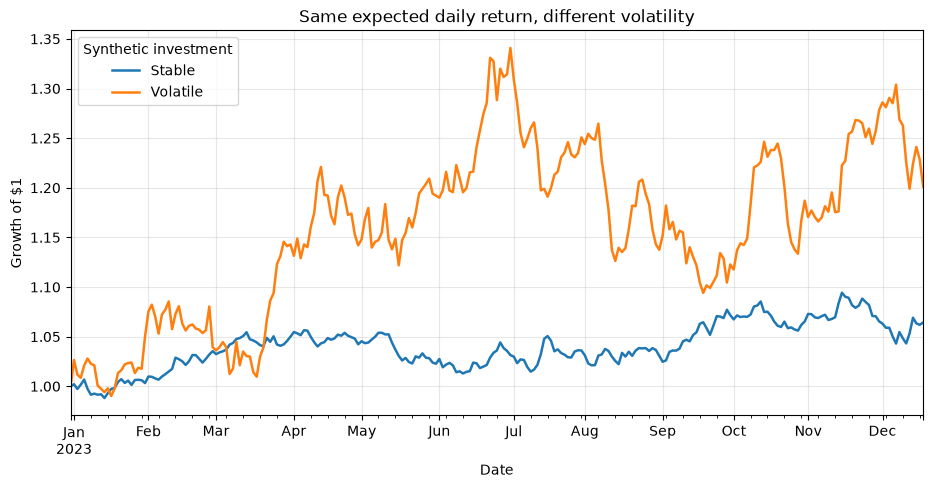

In [3]:
fig, ax = plt.subplots(figsize=(11, 5))
synthetic_growth.plot(ax=ax, linewidth=1.8)
ax.set_title("Same expected daily return, different volatility")
ax.set_ylabel("Growth of $1")
ax.set_xlabel("Date")
ax.legend(title="Synthetic investment")
ax.grid(True, alpha=0.3)
plt.show()

In [4]:
simulation_summary = pd.DataFrame(index=synthetic_daily_returns.columns)
simulation_summary["Sample mean daily return"] = synthetic_daily_returns.mean()
simulation_summary["Annualized arithmetic return"] = (
    synthetic_daily_returns.mean() * TRADING_DAYS
)
simulation_summary["Annualized volatility"] = (
    synthetic_daily_returns.std(ddof=1) * np.sqrt(TRADING_DAYS)
)
simulation_summary["Realized cumulative return"] = synthetic_growth.iloc[-1] - 1

display(simulation_summary.style.format("{:.2%}"))

,Sample mean daily return,Annualized arithmetic return,Annualized volatility,Realized cumulative return
Stable,0.03%,6.51%,7.44%,6.43%
Volatile,0.08%,21.09%,23.48%,20.13%


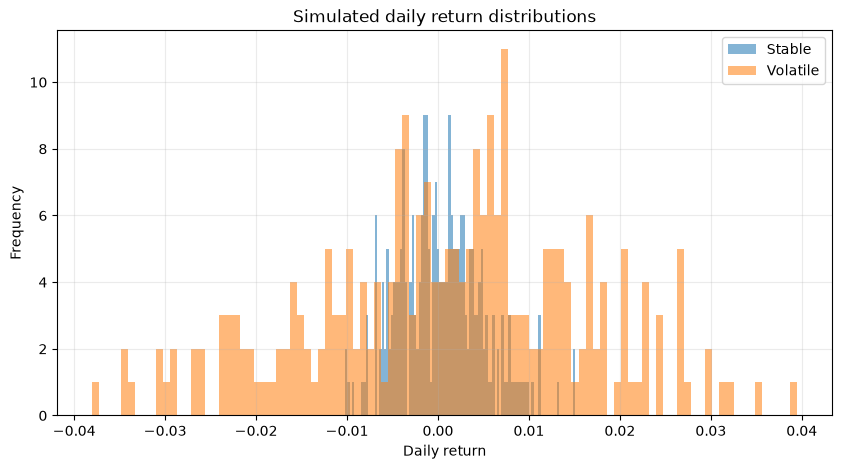

In [15]:
fig, ax = plt.subplots(figsize=(10, 5))
for column in synthetic_daily_returns.columns:
    ax.hist(synthetic_daily_returns[column], bins=100, alpha=0.55, label=column)
ax.set_title("Simulated daily return distributions")
ax.set_xlabel("Daily return")
ax.set_ylabel("Frequency")
ax.legend()
ax.grid(True, alpha=0.25)
plt.show()

### Observations — Part I

- The two series have the **same assumed mean**, not necessarily the same realized sample mean or cumulative return. Random sampling means their outcomes will differ.
- The volatile series should have a wider daily-return distribution and larger swings in its cumulative-growth path.
- Compounding means equal arithmetic average returns do not guarantee equal realized terminal wealth. Volatility can reduce geometric growth, especially when returns fluctuate substantially.
- The result is an illustration, not proof that higher volatility always produces a lower realized ending value over every finite sample. A different random seed or sample period can change the realized paths.

## Part II — Historical portfolio optimization

We now estimate portfolio returns and risk using daily adjusted closing prices from 2019 through 2023. AAPL, MSFT, and AMZN are the investable assets; SPY is used only as a market proxy for beta and is excluded from the optimized portfolio.

### Conventions used throughout this section

| Quantity | Calculation / convention |
|---|---|
| Daily return | Simple close-to-close return, `price.pct_change()` |
| Annualized expected asset return | Mean daily return × 252 (arithmetic annualization, not CAGR) |
| Daily covariance | Sample covariance of daily asset returns |
| Annualized portfolio variance | The existing `portfolio_variance()` function multiplies **daily covariance-based variance by 252** |
| Annualized portfolio volatility | Square root of annualized portfolio variance |
| Risk-free rate | Assumed constant annual rate of 3%, for demonstration |
| Portfolio constraints | Fully invested (weights sum to 1), long-only (each weight between 0 and 1) |

**Important implementation rule:** pass the *daily* covariance matrix into `portfolio_variance()`. Do not annualize the covariance beforehand, because the function already multiplies the result by 252. The function definition is intentionally left unchanged.

In [ ]:
# Download adjusted prices. With auto_adjust=True, the Close field is adjusted.
tickers = ["AAPL", "MSFT", "AMZN", "SPY"]
assets = ["AAPL", "MSFT", "AMZN"]
start_date = "2019-01-01"
end_date = "2024-01-01"  # yfinance end date is exclusive

prices = yf.download(
    tickers=tickers,
    start=start_date,
    end=end_date,
    auto_adjust=True,
    progress=False,
)["Close"]

prices = prices.reindex(columns=tickers).dropna()
daily_returns = prices.pct_change(fill_method=None).dropna()

asset_daily_returns = daily_returns[assets]
market_daily_returns = daily_returns["SPY"]

print(f"Price observations: {len(prices):,}")
print(f"Daily return observations: {len(daily_returns):,}")
print(f"Sample period: {daily_returns.index.min().date()} to {daily_returns.index.max().date()}")
print("Assets:", assets)

Price observations: 1,258
Daily return observations: 1,257
Sample period: 2019-01-03 to 2023-12-29
Assets: ['AAPL', 'MSFT', 'AMZN']


In [7]:
# Annualized arithmetic expected returns and asset-level volatility.
annual_asset_returns = asset_daily_returns.mean() * TRADING_DAYS
annual_asset_volatility = asset_daily_returns.std(ddof=1) * np.sqrt(TRADING_DAYS)

# Keep the covariance matrix DAILY: portfolio_variance() annualizes it internally.
daily_cov_matrix = asset_daily_returns.cov().to_numpy()

# CAPM-style historical beta: Cov(asset, SPY) / Var(SPY), using daily returns.
market_variance_daily = market_daily_returns.var(ddof=1)
asset_betas = pd.Series(
    {
        asset: asset_daily_returns[asset].cov(market_daily_returns) / market_variance_daily
        for asset in assets
    }
).reindex(assets)

risk_free_rate = 0.03  # Annual rate; must be in the same annual units as expected returns.
target_return = 0.00   # Annual minimum acceptable return for the Sortino ratio.

asset_summary = pd.DataFrame(
    {
        "Annualized arithmetic return": annual_asset_returns,
        "Annualized volatility": annual_asset_volatility,
        "Beta vs. SPY": asset_betas,
    }
)
display(asset_summary.style.format({
    "Annualized arithmetic return": "{:.2%}",
    "Annualized volatility": "{:.2%}",
    "Beta vs. SPY": "{:.3f}",
}))

,Annualized arithmetic return,Annualized volatility,Beta vs. SPY
AAPL,37.80%,32.23%,1.235
MSFT,32.03%,30.49%,1.197
AMZN,19.84%,35.22%,1.088


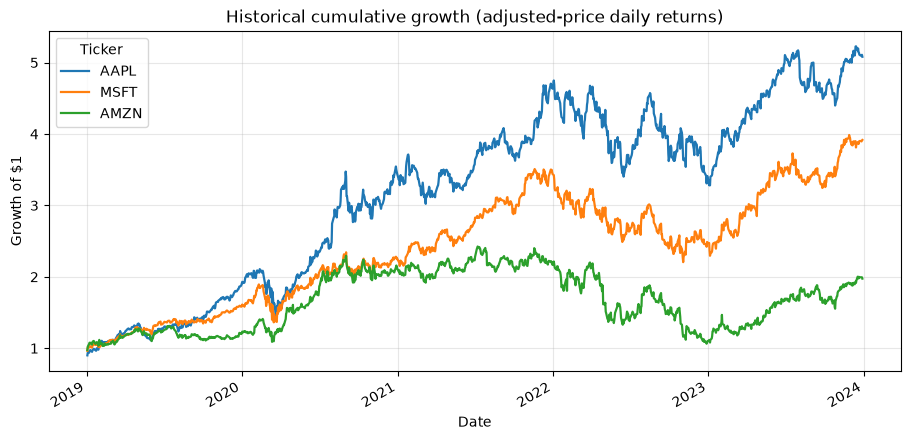

In [ ]:

asset_growth = (1 + asset_daily_returns).cumprod()
fig, ax = plt.subplots(figsize=(11, 5))
asset_growth.plot(ax=ax, linewidth=1.6)
ax.set_title("Historical cumulative growth (adjusted-price daily returns)")
ax.set_ylabel("Growth of $1")
ax.set_xlabel("Date")
ax.grid(True, alpha=0.3)
plt.show()

### Optimization setup

All optimizations use the same asset order, the same sample, and the same long-only fully-invested constraints. This allows the resulting portfolios to be compared on a common basis.

- **Maximum expected return:** maximizes estimated annualized arithmetic return. Under long-only constraints, this will often put all weight on the asset with the highest estimated return; it does not penalize risk.
- **Minimum variance:** minimizes annualized portfolio variance.
- **Maximum Sharpe:** maximizes annual excess return divided by annualized total volatility.
- **Maximum Sortino:** maximizes annual return above the specified minimum acceptable return, divided by annualized downside deviation relative to that target.
- **Maximum Treynor:** maximizes annual excess return per unit of portfolio beta relative to SPY. Beta is the weighted average of the asset betas.

These are different objectives, so it is expected that they may produce different weights.

In [9]:
# Constraints: weights sum to 1 and every weight is between 0 and 1.
num_assets = len(assets)
initial_guess = np.full(num_assets, 1.0 / num_assets)
bounds = tuple((0.0, 1.0) for _ in range(num_assets))
constraints = ({"type": "eq", "fun": lambda weights: np.sum(weights) - 1.0},)

In [10]:
# Maximize expected return by minimizing its negative.
def portfolio_returns(weights, mean_returns):
    return mean_returns @ weights

def negative_portfolio_returns(weights, mean_returns):
    return -portfolio_returns(weights, mean_returns)


# Function intentionally unchanged.
# It expects DAILY covariance and returns ANNUALIZED portfolio variance.
def portfolio_variance(weights, cov_matrix):
    return (weights.T @ cov_matrix @ weights) * 252


def sharpe_ratio(weights, mean_returns, cov_matrix, risk_free_rate=0.03):
    portfolio_return = portfolio_returns(weights, mean_returns)
    portfolio_vol = np.sqrt(portfolio_variance(weights, cov_matrix))
    return (portfolio_return - risk_free_rate) / portfolio_vol


def neg_sharpe_ratio(weights, mean_returns, cov_matrix, risk_free_rate=0.03):
    return -sharpe_ratio(weights, mean_returns, cov_matrix, risk_free_rate)


def sortino_ratio(weights, asset_daily_returns, target_return=0.0):
    portfolio_daily_returns = asset_daily_returns @ weights
    annual_portfolio_return = portfolio_daily_returns.mean() * TRADING_DAYS

    # Convert the annual arithmetic target to a daily target for daily observations.
    target_daily_return = target_return / TRADING_DAYS

    # Downside deviation uses every observation; observations above target contribute zero.
    downside_returns = np.minimum(
        portfolio_daily_returns.to_numpy() - target_daily_return, 0.0
    )
    downside_deviation_annual = (
        np.sqrt(np.mean(np.square(downside_returns))) * np.sqrt(TRADING_DAYS)
    )
    if downside_deviation_annual <= 0:
        return np.nan
    return (annual_portfolio_return - target_return) / downside_deviation_annual


def neg_sortino_ratio(weights, asset_daily_returns, target_return=0.0):
    ratio = sortino_ratio(weights, asset_daily_returns, target_return)
    # A zero downside deviation makes the ratio undefined.
    return -ratio if np.isfinite(ratio) else 1e6


def treynor_ratio(weights, mean_returns, betas, risk_free_rate):
    portfolio_return = mean_returns @ weights
    portfolio_beta = np.asarray(betas) @ weights
    if portfolio_beta <= 0:
        return np.nan
    return (portfolio_return - risk_free_rate) / portfolio_beta


def neg_treynor_ratio(weights, mean_returns, betas, risk_free_rate):
    ratio = treynor_ratio(weights, mean_returns, betas, risk_free_rate)
    return -ratio if np.isfinite(ratio) else 1e6

In [11]:
def optimize_max_return(mean_returns, constraints, bounds, init_guess):
    return minimize(
        negative_portfolio_returns,
        init_guess,
        args=(mean_returns,),
        method="SLSQP",
        bounds=bounds,
        constraints=constraints,
    )


def optimize_min_risk(daily_cov, constraints, bounds, init_guess):
    return minimize(
        portfolio_variance,
        init_guess,
        args=(daily_cov,),
        method="SLSQP",
        bounds=bounds,
        constraints=constraints,
    )


def optimize_max_sharpe(mean_returns, daily_cov, risk_free_rate, bounds, constraints, init_guess):
    return minimize(
        neg_sharpe_ratio,
        init_guess,
        args=(mean_returns, daily_cov, risk_free_rate),
        method="SLSQP",
        bounds=bounds,
        constraints=constraints,
    )


def optimize_max_sortino(asset_daily_returns, target_return, constraints, bounds, init_guess):
    return minimize(
        neg_sortino_ratio,
        init_guess,
        args=(asset_daily_returns, target_return),
        method="SLSQP",
        bounds=bounds,
        constraints=constraints,
    )


def optimize_max_treynor(mean_returns, betas, risk_free_rate, constraints, bounds, init_guess):
    return minimize(
        neg_treynor_ratio,
        init_guess,
        args=(mean_returns, betas, risk_free_rate),
        method="SLSQP",
        bounds=bounds,
        constraints=constraints,
    )

In [12]:
# Optimize each objective using the same daily covariance matrix and annual return estimates.
result_max_return = optimize_max_return(
    annual_asset_returns.to_numpy(), constraints, bounds, initial_guess
)
result_min_risk = optimize_min_risk(
    daily_cov_matrix, constraints, bounds, initial_guess
)
result_max_sharpe = optimize_max_sharpe(
    annual_asset_returns.to_numpy(), daily_cov_matrix,
    risk_free_rate, bounds, constraints, initial_guess
)
result_max_sortino = optimize_max_sortino(
    asset_daily_returns, target_return, constraints, bounds, initial_guess
)
result_max_treynor = optimize_max_treynor(
    annual_asset_returns.to_numpy(), asset_betas.to_numpy(),
    risk_free_rate, constraints, bounds, initial_guess
)

optimization_results = {
    "Maximum expected return": result_max_return,
    "Minimum variance": result_min_risk,
    "Maximum Sharpe": result_max_sharpe,
    "Maximum Sortino": result_max_sortino,
    "Maximum Treynor": result_max_treynor,
}

for name, result in optimization_results.items():
    print(f"{name}: success={result.success}; message={result.message}")

Maximum expected return: success=True; message=Optimization terminated successfully
Minimum variance: success=True; message=Optimization terminated successfully
Maximum Sharpe: success=True; message=Optimization terminated successfully
Maximum Sortino: success=True; message=Optimization terminated successfully
Maximum Treynor: success=True; message=Optimization terminated successfully


### How to read the results

The optimizer's `fun` field is the value of the *minimized objective*. For ratio objectives, the code minimizes the **negative** ratio, so the corresponding positive ratio is `-result.fun`. The comparison table below recalculates each portfolio's metrics directly from its weights so that every row uses the same formulas and annualization conventions.

In [13]:
def calculate_portfolio_metrics(
    weights,
    asset_daily_returns,
    annual_asset_returns,
    daily_cov,
    asset_betas,
    risk_free_rate,
    target_return,
):
    portfolio_daily_returns = asset_daily_returns.to_numpy() @ weights
    annual_return = float(annual_asset_returns.to_numpy() @ weights)
    annual_volatility = float(np.sqrt(portfolio_variance(weights, daily_cov)))

    sharpe = (
        (annual_return - risk_free_rate) / annual_volatility
        if annual_volatility > 0 else np.nan
    )

    target_daily_return = target_return / TRADING_DAYS
    downside_returns = np.minimum(portfolio_daily_returns - target_daily_return, 0.0)
    downside_deviation = (
        np.sqrt(np.mean(np.square(downside_returns))) * np.sqrt(TRADING_DAYS)
    )
    sortino = (
        (annual_return - target_return) / downside_deviation
        if downside_deviation > 0 else np.nan
    )

    portfolio_beta = float(asset_betas.to_numpy() @ weights)
    treynor = (
        (annual_return - risk_free_rate) / portfolio_beta
        if portfolio_beta > 0 else np.nan
    )

    return {
        "Expected annual return": annual_return,
        "Annual volatility": annual_volatility,
        "Portfolio beta": portfolio_beta,
        "Sharpe ratio": sharpe,
        "Sortino ratio": sortino,
        "Treynor ratio": treynor,
    }


portfolio_weights = {
    name: result.x for name, result in optimization_results.items()
}
portfolio_weights["Equal-weight benchmark"] = initial_guess.copy()

weights_table = pd.DataFrame(portfolio_weights, index=assets).T
metrics_table = pd.DataFrame(
    {
        name: calculate_portfolio_metrics(
            weights,
            asset_daily_returns,
            annual_asset_returns,
            daily_cov_matrix,
            asset_betas,
            risk_free_rate,
            target_return,
        )
        for name, weights in portfolio_weights.items()
    }
).T

print("Portfolio weights")
display(weights_table.style.format("{:.2%}"))

print("Portfolio performance and risk metrics")
display(metrics_table.style.format({
    "Expected annual return": "{:.2%}",
    "Annual volatility": "{:.2%}",
    "Portfolio beta": "{:.3f}",
    "Sharpe ratio": "{:.3f}",
    "Sortino ratio": "{:.3f}",
    "Treynor ratio": "{:.3f}",
}))

Portfolio weights


,AAPL,MSFT,AMZN
Maximum expected return,100.00%,0.00%,0.00%
Minimum variance,31.81%,47.24%,20.95%
Maximum Sharpe,71.75%,28.25%,0.00%
Maximum Sortino,72.18%,27.82%,0.00%
Maximum Treynor,100.00%,0.00%,0.00%
Equal-weight benchmark,33.33%,33.33%,33.33%


Portfolio performance and risk metrics


,Expected annual return,Annual volatility,Portfolio beta,Sharpe ratio,Sortino ratio,Treynor ratio
Maximum expected return,37.80%,32.23%,1.235,1.080,1.734,0.282
Minimum variance,31.31%,28.81%,1.187,0.983,1.581,0.239
Maximum Sharpe,36.17%,30.19%,1.225,1.099,1.760,0.271
Maximum Sortino,36.20%,30.21%,1.225,1.099,1.760,0.271
Maximum Treynor,37.80%,32.23%,1.235,1.080,1.734,0.282
Equal-weight benchmark,29.89%,29.01%,1.174,0.927,1.494,0.229


In [14]:
# Compact, data-dependent observations from this sample.
print("Highest estimated-return portfolio:",
      metrics_table["Expected annual return"].idxmax())
print("Lowest-volatility portfolio:",
      metrics_table["Annual volatility"].idxmin())
print("Highest Sharpe portfolio:",
      metrics_table["Sharpe ratio"].idxmax())
print("Highest Sortino portfolio:",
      metrics_table["Sortino ratio"].idxmax())
print("Highest Treynor portfolio:",
      metrics_table["Treynor ratio"].idxmax())

Highest estimated-return portfolio: Maximum expected return
Lowest-volatility portfolio: Minimum variance
Highest Sharpe portfolio: Maximum Sharpe
Highest Sortino portfolio: Maximum Sortino
Highest Treynor portfolio: Maximum expected return


### Interpretation guide

Use the results table to answer these questions after running the notebook:

1. **Maximum expected return vs. minimum variance:** how much annualized volatility is given up (or accepted) to maximize the historical mean return? Is the maximum-return solution concentrated in one asset?
2. **Maximum Sharpe:** does it improve excess return per unit of total volatility relative to the equal-weight benchmark?
3. **Maximum Sortino:** does it improve the ratio using downside deviation, and does its weight allocation differ materially from the Sharpe portfolio?
4. **Maximum Treynor:** does it select a different portfolio because systematic risk (beta) rather than total volatility is the denominator?
5. **Robustness:** small changes in sample dates, estimated means, and covariance can change optimized weights significantly. Compare the weights as well as the ratios; a marginally higher in-sample metric is not proof of a better future portfolio.

### Important limitations

- The expected returns and betas are estimates from the same historical sample used for optimization. This is an **in-sample** exercise and can overfit estimation noise.
- `mean(daily returns) × 252` is an annualized arithmetic mean, not the realized compound annual growth rate (CAGR).
- Volatility is annualized using the conventional square-root-of-time rule. This assumes daily returns are sufficiently stable over time and does not capture all forms of serial dependence or changing volatility.
- The 3% risk-free rate is a constant assumption, not a matched historical Treasury series.
- SPY is the beta benchmark, not a constrained investment in these portfolios. The optimized universe is AAPL, MSFT, and AMZN only.
- This notebook does not yet include transaction costs, taxes, out-of-sample testing, turnover limits, or parameter uncertainty.

## Part 3 — Visualizing the Feasible Portfolio Set and Efficient Frontier

In the previous sections, we compared portfolio performance under different optimization objectives, including maximum return, minimum variance, maximum Sharpe ratio, maximum Sortino ratio, and maximum Treynor ratio.

In this section, we visualize the relationship between portfolio return and risk. We generate 5,000 random portfolios using different combinations of AAPL, AMZN, and MSFT, subject to the constraints that short selling is not allowed and portfolio weights sum to one.

For each portfolio, we calculate its expected annual return, annualized volatility, and Sharpe ratio. We then plot the portfolios in mean-variance space, using volatility on the horizontal axis and expected return on the vertical axis.

The resulting scatter plot illustrates the feasible set of portfolios under our constraints. Its upper boundary provides an approximation of the mean-variance efficient frontier: portfolios that offer the highest expected return for a given level of volatility.

Finally, we overlay the optimized portfolios to compare how different objectives affect portfolio weights, expected returns, and risk.

In [31]:

cov_matrix_annual = asset_daily_returns.cov().to_numpy() *252

num_assets = len(assets)

# Check dimensions and annualization inputs
print("Assets:", assets)
print("Mean returns shape:", annual_asset_returns.shape)
print("Covariance matrix shape:", cov_matrix_annual.shape)
print("Risk-free rate:", risk_free_rate)
print("Mean annual returns:", annual_asset_returns)



Assets: ['AAPL', 'AMZN', 'MSFT']
Mean returns shape: (3,)
Covariance matrix shape: (3, 3)
Risk-free rate: 0.03
Mean annual returns: Ticker
AAPL    0.378031
MSFT    0.320295
AMZN    0.198360
dtype: float64


In [32]:

def portfolio_performance(weights, mean_returns, cov_matrix):
    expected_return = mean_returns @ weights

    volatility = np.sqrt(
        weights.T @ cov_matrix @ weights
    )

    return expected_return, volatility


# Test with an equal-weight portfolio
test_weights = np.ones(num_assets) / num_assets

test_return, test_volatility = portfolio_performance(
    test_weights,
    annual_asset_returns,
    cov_matrix_annual
)

print(f"Weights sum: {test_weights.sum():.4f}")
print(f"Expected annual return: {test_return:.2%}")
print(f"Annualized volatility: {test_volatility:.2%}")
print(
    f"Sharpe ratio: "
    f"{(test_return - risk_free_rate) / test_volatility:.4f}"
)



Weights sum: 1.0000
Expected annual return: 29.89%
Annualized volatility: 29.01%
Sharpe ratio: 0.9269


### 3.1 Generating Random Portfolios

To visualize the feasible portfolio set, we generate 5,000 random portfolios with non-negative weights that sum to one. Each portfolio represents a different allocation across AAPL, AMZN, and MSFT.

We use a Dirichlet distribution to generate valid portfolio weights. For each allocation, we calculate expected annual return, annualized volatility, and the Sharpe ratio.

These simulated portfolios provide an approximation of the feasible risk-return space. The upper boundary helps illustrate the efficient frontier, although random sampling does not guarantee that the exact frontier will be identified.

In [33]:

# Generate random portfolios
num_portfolios = 5000

rng = np.random.default_rng(42)

random_weights = rng.dirichlet(
    np.ones(num_assets),
    size=num_portfolios
)

# Store portfolio metrics
portfolio_results = np.zeros((num_portfolios, 3))

for i, weights in enumerate(random_weights):
    portfolio_return, portfolio_volatility = portfolio_performance(
        weights,
        annual_asset_returns,
        cov_matrix_annual
    )

    sharpe = (
        portfolio_return - risk_free_rate
    ) / portfolio_volatility

    portfolio_results[i] = [
        portfolio_volatility,
        portfolio_return,
        sharpe
    ]

# Convert results to a DataFrame
random_portfolios_df = pd.DataFrame(
    portfolio_results,
    columns=["Volatility", "Return", "Sharpe Ratio"]
)

random_portfolios_df.head()


,Volatility,Return,Sharpe Ratio
0,0.290167,0.298965,0.926933
1,0.325158,0.231793,0.620600
2,0.292721,0.335844,1.044831
3,0.302014,0.287491,0.852579
4,0.295997,0.305305,0.930095


### 3.2 Visualizing the Feasible Portfolio Set

We plot the simulated portfolios using annualized volatility as the measure of risk and expected annual return as the measure of performance. Each point represents a feasible allocation across AAPL, AMZN, and MSFT.

The color of each point represents its Sharpe ratio. This allows us to compare risk-adjusted performance across the feasible portfolio set and identify regions where portfolios offer better compensation for risk.

The upper boundary of the scatter plot approximates the mean-variance efficient frontier. Portfolios below this boundary are inefficient in mean-variance terms because another portfolio can offer a higher expected return at the same level of volatility, or lower volatility for the same expected return.

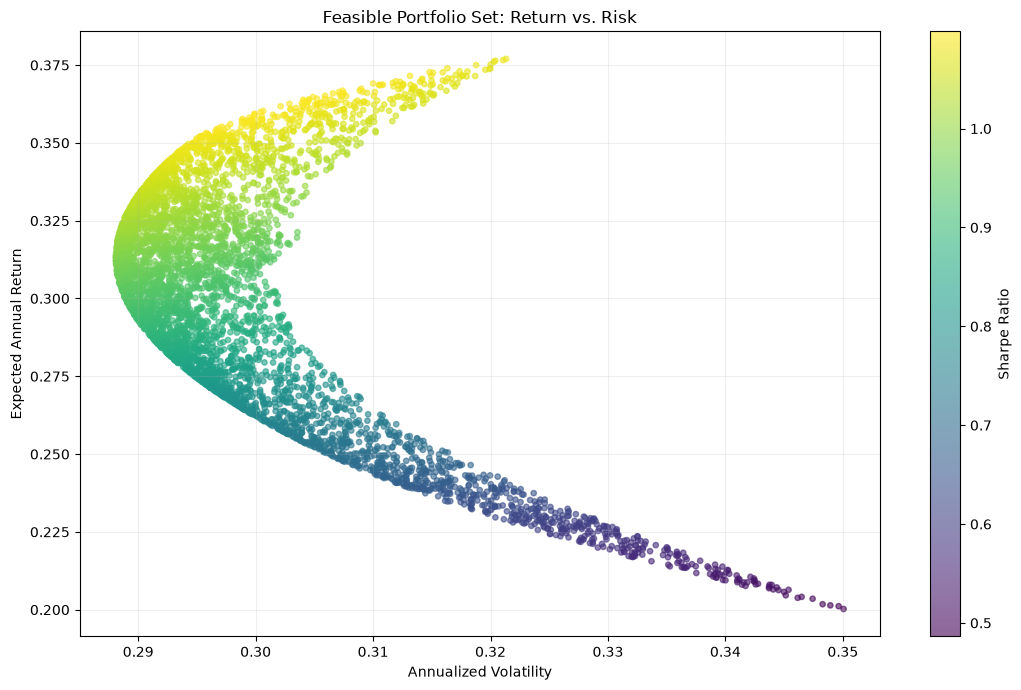

In [36]:

import matplotlib.pyplot as plt

plt.figure(figsize=(11, 7))

scatter = plt.scatter(
    random_portfolios_df["Volatility"],
    random_portfolios_df["Return"],
    c=random_portfolios_df["Sharpe Ratio"],
    cmap="viridis",
    alpha=0.6,
    s=15
)

plt.colorbar(scatter, label="Sharpe Ratio")
plt.xlabel("Annualized Volatility")
plt.ylabel("Expected Annual Return")
plt.title("Feasible Portfolio Set: Return vs. Risk")
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()


### 3.3 Comparing Optimized Portfolios with the Feasible Set

We overlay the five optimized portfolios on the simulated portfolio set. Each optimized portfolio represents the solution to a different objective function: maximum expected return, minimum variance, maximum Sharpe ratio, maximum Sortino ratio, or maximum Treynor ratio.

Their positions illustrate how the choice of optimization objective influences the trade-off between expected return and risk.

The optimized portfolios should be interpreted in the context of their respective objectives. A portfolio that maximizes expected return does not necessarily maximize risk-adjusted performance, while a minimum-variance portfolio prioritizes lower volatility rather than higher returns.

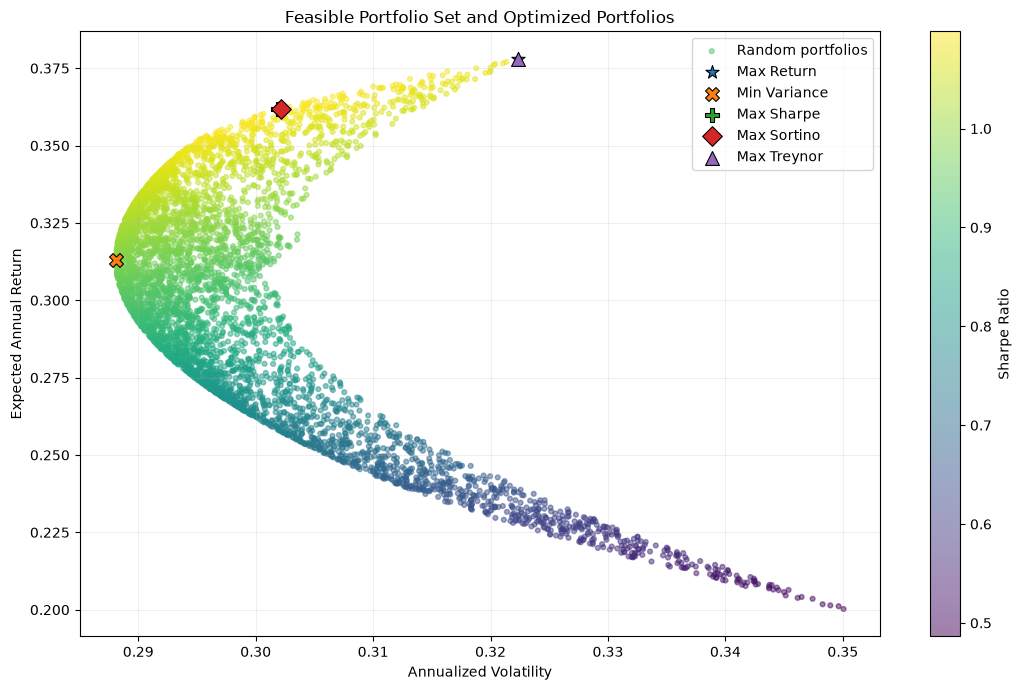

In [42]:

portfolios_to_plot = {
    "Max Return": result_max_return.x,
    "Min Variance": result_min_risk.x,
    "Max Sharpe": result_max_sharpe.x,
    "Max Sortino": result_max_sortino.x,
    "Max Treynor": result_max_treynor.x
}

markers = ["*", "X", "P", "D", "^"]

plt.figure(figsize=(11, 7))

scatter = plt.scatter(
    random_portfolios_df["Volatility"],
    random_portfolios_df["Return"],
    c=random_portfolios_df["Sharpe Ratio"],
    cmap="viridis",
    alpha=0.5,
    s=12,
    label="Random portfolios"
)

plt.colorbar(scatter, label="Sharpe Ratio")

for (name, weights), marker in zip(
    portfolios_to_plot.items(), markers
):
    port_return, port_volatility = portfolio_performance(
        weights,
        annual_asset_returns,
        cov_matrix_annual
    )

    plt.scatter(
        port_volatility,
        port_return,
        marker=marker,
        s=100,
        edgecolors="black",
        linewidths=0.8,
        label=name
    )

plt.xlabel("Annualized Volatility")
plt.ylabel("Expected Annual Return")
plt.title("Feasible Portfolio Set and Optimized Portfolios")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()


In [48]:
print("Max Sharpe objective:", result_max_sharpe.fun)
print("Max Sortino objective:", result_max_sortino.fun)

print("Max Sharpe success:", result_max_sharpe.success)
print("Max Sortino success:", result_max_sortino.success)

Max Sharpe objective: -1.098811606004475
Max Sortino objective: -1.760013954583841
Max Sharpe success: True
Max Sortino success: True


In [49]:
print(
    "Sortino ratio at Max Sharpe weights:",
    sortino_ratio(result_max_sharpe.x, asset_daily_returns, target_return)
)

print(
    "Sortino ratio at Max Sortino weights:",
    sortino_ratio(result_max_sortino.x, asset_daily_returns, target_return)
)

Sortino ratio at Max Sharpe weights: 1.7600066201764952
Sortino ratio at Max Sortino weights: 1.760013954583841


In [50]:
print(
    "Sharpe ratio at Max Sharpe weights:",
    sharpe_ratio(
        result_max_sharpe.x,
        annual_asset_returns.to_numpy(),
        daily_cov_matrix,
        risk_free_rate
    )
)

print(
    "Sharpe ratio at Max Sortino weights:",
    sharpe_ratio(
        result_max_sortino.x,
        annual_asset_returns.to_numpy(),
        daily_cov_matrix,
        risk_free_rate
    )
)

Sharpe ratio at Max Sharpe weights: 1.098811606004475
Sharpe ratio at Max Sortino weights: 1.0988070692099345
